# Explore agent traces

Load the recorded trajectories, examine run and issue identifiers, and inspect one agent attempt step by step. Run cells in order.

## 1. Setup

The notebook imports the trace adapter from the adjacent lab directory. Restart the kernel after changing its Python files.

In [ ]:
import logging
from dataclasses import asdict
import sys
from pathlib import Path

import pandas as pd
from datasets import load_dataset
from IPython.display import display

logging.basicConfig(level=logging.INFO)

In [3]:
from interfaces import (
    SWEGymTraceAdapter, join_trace_tasks, plot_message_distributions,
    plot_trace_distributions, structure_trace_ids, summarize_trace_messages,
)

pd.set_option("display.max_colwidth", 120)

## 2. Load the dataset

Each row is one attempt at a software issue. This loads the complete `train.raw` split.

In [ ]:
dataset_name = "SWE-Gym/OpenHands-Sampled-Trajectories"
split = "train.raw"
print(f"[STAGE] Load {dataset_name} / {split}")
dataset = load_dataset(dataset_name, split=split)
print(f"✓ Records: {len(dataset):,}")
print("Fields:", dataset.column_names)

[STAGE] Load SWE-Gym/OpenHands-Sampled-Trajectories / train.raw
✓ Records: 6,055
Fields: ['instance_id', 'run_id', 'resolved', 'messages', 'tools', 'test_result']


## 3. Inspect one record

Change `sample_index` to inspect a different attempt. The messages and evaluation report are displayed separately below.

In [5]:
sample_index = 0
sample = dataset[sample_index]
print(f"[STAGE] Inspect record {sample_index}")
print("✓ Fields:", list(sample))
display(pd.Series({key: sample.get(key) for key in ["instance_id", "run_id", "resolved"]}, name="value").to_frame())
print("Messages:", len(sample.get("messages") or []))
print("Available tools:", [tool.get("function", {}).get("name") for tool in (sample.get("tools") or [])])

[STAGE] Inspect record 0
✓ Fields: ['instance_id', 'run_id', 'resolved', 'messages', 'tools', 'test_result']


,value
instance_id,getmoto__moto-5321
run_id,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1
resolved,False


Messages: 13
Available tools: ['execute_bash', 'finish', 'str_replace_editor']


## 4. Structure run and issue IDs

`run_config` keeps labels such as `N`, `no-hint`, and `t02` as text. Their meaning is not assumed. Missing parsed fields indicate an unrecognized ID format.

In [6]:
print("[STAGE] Parse run and instance IDs")
trace_df, run_df, instance_df = structure_trace_ids(
    dataset.select_columns(["instance_id", "run_id", "resolved"]).to_pandas()
)
print(f"✓ Attempts: {len(trace_df):,} | unique issues: {len(instance_df):,} | unique runs: {len(run_df):,}")
print(f"Unparsed runs: {run_df['max_iterations'].isna().sum()} | unparsed issues: {instance_df['issue_number'].isna().sum()}")
display(trace_df.head(10))

INFO:trace_analysis:Structured 6055 traces into 9 runs and 2438 issues


[STAGE] Parse run and instance IDs
✓ Attempts: 6,055 | unique issues: 2,438 | unique runs: 9
Unparsed runs: 0 | unparsed issues: 0


,instance_id,run_id,resolved,model_name,model_date,max_iterations,run_config,run_number,owner,repository,issue_number
0,getmoto__moto-5321,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5321
1,getmoto__moto-5699,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5699
2,getmoto__moto-7495,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,7495
3,getmoto__moto-5545,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5545
4,getmoto__moto-5020,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5020
5,getmoto__moto-5752,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5752
6,getmoto__moto-7607,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,7607
7,getmoto__moto-6317,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,6317
8,getmoto__moto-5794,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,getmoto,moto,5794
9,python__mypy-15208,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1,python,mypy,15208


In [7]:
print("[STAGE] Inspect run configurations")
display(run_df)
print("✓ One row per unique run ID")

[STAGE] Inspect run configurations


,run_id,model_name,model_date,max_iterations,run_config,run_number
0,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t04,1
1,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t03-run_1,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t03,1
2,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t02-run_1,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t02,1
3,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t05-run_1,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t05,1
4,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t08-run_1,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t08,1
5,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t0-run_1,gpt-4o,2024-08-06,30,N_v2.1-no-hint-train-t0,1
6,gpt-4o-2024-08-06_maxiter_50_N_v2.1-no-hint-train-t0-run_1,gpt-4o,2024-08-06,50,N_v2.1-no-hint-train-t0,1
7,claude-3-5-sonnet-20241022_maxiter_50_N_v2.1-no-hint-run_1,claude-3-5-sonnet,20241022,50,N_v2.1-no-hint,1
8,gpt-4o-2024-08-06_maxiter_50_N_v2.1-no-hint-train-t1-run_1,gpt-4o,2024-08-06,50,N_v2.1-no-hint-train-t1,1


✓ One row per unique run ID


## 4a. Join traces with their SWE-Gym tasks

Join all trajectory records to the original issue using `instance_id`. Each trace keeps its own `trace_row`, even when run IDs repeat. A left join keeps traces with no matching task. Task columns use the `task_` prefix.

`task_patch` and `task_test_patch` are reference information for inspection and evaluation; keep them out of model-visible training prompts.

[STAGE] Load task dataset: SWE-Gym/SWE-Gym


INFO:trace_analysis:Joined 6055 traces: matched=6055 unmatched=0


✓ Joined 6,055 traces with 2,438 task records
Task match counts: {'both': 6055, 'left_only': 0, 'right_only': 0}
Unmatched issue IDs: 0


,trace_row,instance_id,run_id,resolved,task_match
0,0,getmoto__moto-5321,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,both
1,1,getmoto__moto-5699,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,both
2,2,getmoto__moto-7495,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,both
3,3,getmoto__moto-5545,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,both
4,4,getmoto__moto-5020,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,both
5,5,getmoto__moto-5752,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,both
6,6,getmoto__moto-7607,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,both
7,7,getmoto__moto-6317,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,both
8,8,getmoto__moto-5794,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,both
9,9,python__mypy-15208,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,both


,trace_row,instance_id,run_id,resolved,messages,tools,test_result,task_hints_text,task_patch,task_test_patch,task_created_at,task_problem_statement,task_repo,task_base_commit,task_version,task_PASS_TO_PASS,task_FAIL_TO_PASS,task_match
0,0,getmoto__moto-5321,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,[{'content': 'You are a helpful assistant that can interact with a computer to solve tasks. <IMPORTANT> * If user pr...,[{'function': {'description': 'Execute a bash command in the terminal. * Long running commands: For commands that ma...,"{'apply_patch_output': None, 'git_patch': '', 'report': {'empty_generation': True, 'error_eval': False, 'failed_appl...",,"diff --git a/moto/rds/models.py b/moto/rds/models.py\n--- a/moto/rds/models.py\n+++ b/moto/rds/models.py\n@@ -1796,6...",diff --git a/tests/test_rds/test_rds_clusters.py b/tests/test_rds/test_rds_clusters.py\n--- a/tests/test_rds/test_rd...,2022-07-22 14:16:52,KeyError: 'clustername' (instead of `DBClusterNotFoundFault`) thrown when calling `describe_db_clusters` for a non-e...,getmoto/moto,036cc6879e81341a16c3574faf7b64e4e14e29be,3.1,"[tests/test_rds/test_rds_clusters.py::test_start_db_cluster_without_stopping, tests/test_rds/test_rds_clusters.py::t...",[tests/test_rds/test_rds_clusters.py::test_describe_db_cluster_fails_for_non_existent_cluster],both
1,1,getmoto__moto-5699,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,[{'content': 'You are a helpful assistant that can interact with a computer to solve tasks. <IMPORTANT> * If user pr...,[{'function': {'description': 'Execute a bash command in the terminal. * Long running commands: For commands that ma...,"{'apply_patch_output': None, 'git_patch': '', 'report': {'empty_generation': True, 'error_eval': False, 'failed_appl...",,diff --git a/moto/cloudfront/responses.py b/moto/cloudfront/responses.py\n--- a/moto/cloudfront/responses.py\n+++ b/...,diff --git a/tests/test_cloudfront/test_cloudfront_invalidation.py b/tests/test_cloudfront/test_cloudfront_invalidat...,2022-11-22 15:04:13,CloudFront: list_invalidations includes empty element if no invalidations\n## How to reproduce the issue\r\n\r\n```p...,getmoto/moto,b4f59b771cc8a89976cbea8c889758c132d405d0,4.0,"[tests/test_cloudfront/test_cloudfront_invalidation.py::test_list_invalidations, tests/test_cloudfront/test_cloudfro...",[tests/test_cloudfront/test_cloudfront_invalidation.py::test_list_invalidations__no_entries],both
2,2,getmoto__moto-7495,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,[{'content': 'You are a helpful assistant that can interact with a computer to solve tasks. <IMPORTANT> * If user pr...,[{'function': {'description': 'Execute a bash command in the terminal. * Long running commands: For commands that ma...,"{'apply_patch_output': None, 'git_patch': '', 'report': {'empty_generation': True, 'error_eval': False, 'failed_appl...",,diff --git a/moto/ec2/responses/instances.py b/moto/ec2/responses/instances.py\n--- a/moto/ec2/responses/instances.p...,diff --git a/tests/test_ec2/test_instances.py b/tests/test_ec2/test_instances.py\n--- a/tests/test_ec2/test_instance...,2024-03-19 23:21:20,"StateTransitionReason has no value after stopping an instance\nHi All,\r\n\r\nI am struggling with getting moto 5.0....",getmoto/moto,009d0191f9591c4d4b44c3b94f54bb69bb3c05b2,5.0,"[tests/test_ec2/test_instances.py::test_run_instance_with_block_device_mappings_missing_ebs, tests/test_ec2/test_ins...",[tests/test_ec2/test_instances.py::test_instance_start_and_stop],both
3,3,getmoto__moto-5545,gpt-4o-2024-08-06_maxiter_30_N_v2.1-no-hint-train-t04-run_1,False,[{'content': 'You are a helpful assistant that can interact with a computer to solve tasks. <IMPORTANT> * If user pr...,[{'function': {'description': 'Execute a bash command in the terminal. * Long running commands: For commands that ma...,"{'apply_patch_output': None, 'git_patch': '', 'report': {'empty_generation': True, 'error_eval': False, 'failed_appl...","Hi @h

### Inspect a question and its trace

Choose an `instance_id`, then an attempt number from the displayed rows. Each `trace_row` identifies one recorded attempt, even when run IDs repeat. The message table below belongs to the selected question and attempt.

In [ ]:
issue_id = "getmoto__moto-5321"  # Change this to another instance_id.
attempt_number = 0  # Select a row from the attempts table (starting at 0).

attempts = joined_df.loc[joined_df["instance_id"] == issue_id].reset_index(drop=True)
if attempts.empty:
    raise ValueError(f"No traces found for {issue_id}")
if not 0 <= attempt_number < len(attempts):
    raise IndexError(f"Choose an attempt_number from 0 to {len(attempts) - 1}")

print(f"[STAGE] Attempts for {issue_id}")
display(attempts[["trace_row", "run_id", "resolved", "task_match"]])
joined_sample = attempts.iloc[attempt_number]
sample_index = int(joined_sample["trace_row"])
sample = dataset[sample_index]
print(f"✓ Selected attempt {attempt_number} | trace row {sample_index} | match: {joined_sample['task_match']}")
print("\n--- Original question ---\n")
print(joined_sample.get("task_problem_statement"))

In [ ]:
print(f"[STAGE] Trace for {issue_id}, attempt {attempt_number}")
trace = SWEGymTraceAdapter().parse(sample)
messages = [asdict(message) for message in trace.messages]
message_df = pd.DataFrame(messages)
print(f"✓ {len(messages)} messages, in order")
display(message_df[["index", "role", "content", "tool_call_id", "tool_calls"]])

The reference solution is available separately as `joined_sample["task_patch"]`. It is evaluation information.

## 5. Outcome distribution

`resolved` is the evaluation label for each attempt. Missing labels are included.

In [11]:
print("[STAGE] Count outcomes")
outcomes = trace_df["resolved"].value_counts(dropna=False).rename_axis("resolved").to_frame("attempts")
outcomes["percent"] = (outcomes["attempts"] / len(trace_df) * 100).round(1)
display(outcomes)
print(f"✓ Counted {outcomes['attempts'].sum():,} attempts")

[STAGE] Count outcomes


,attempts,percent
resolved,,
False,5564,91.9
True,491,8.1


✓ Counted 6,055 attempts


## 5a. Dataset distributions

These plots count **attempts** in the full loaded split. Repositories show the top 15 by attempt count. Model and repository categories with missing values are labeled `Unknown`.

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


[STAGE] Plot distributions for 6,055 attempts


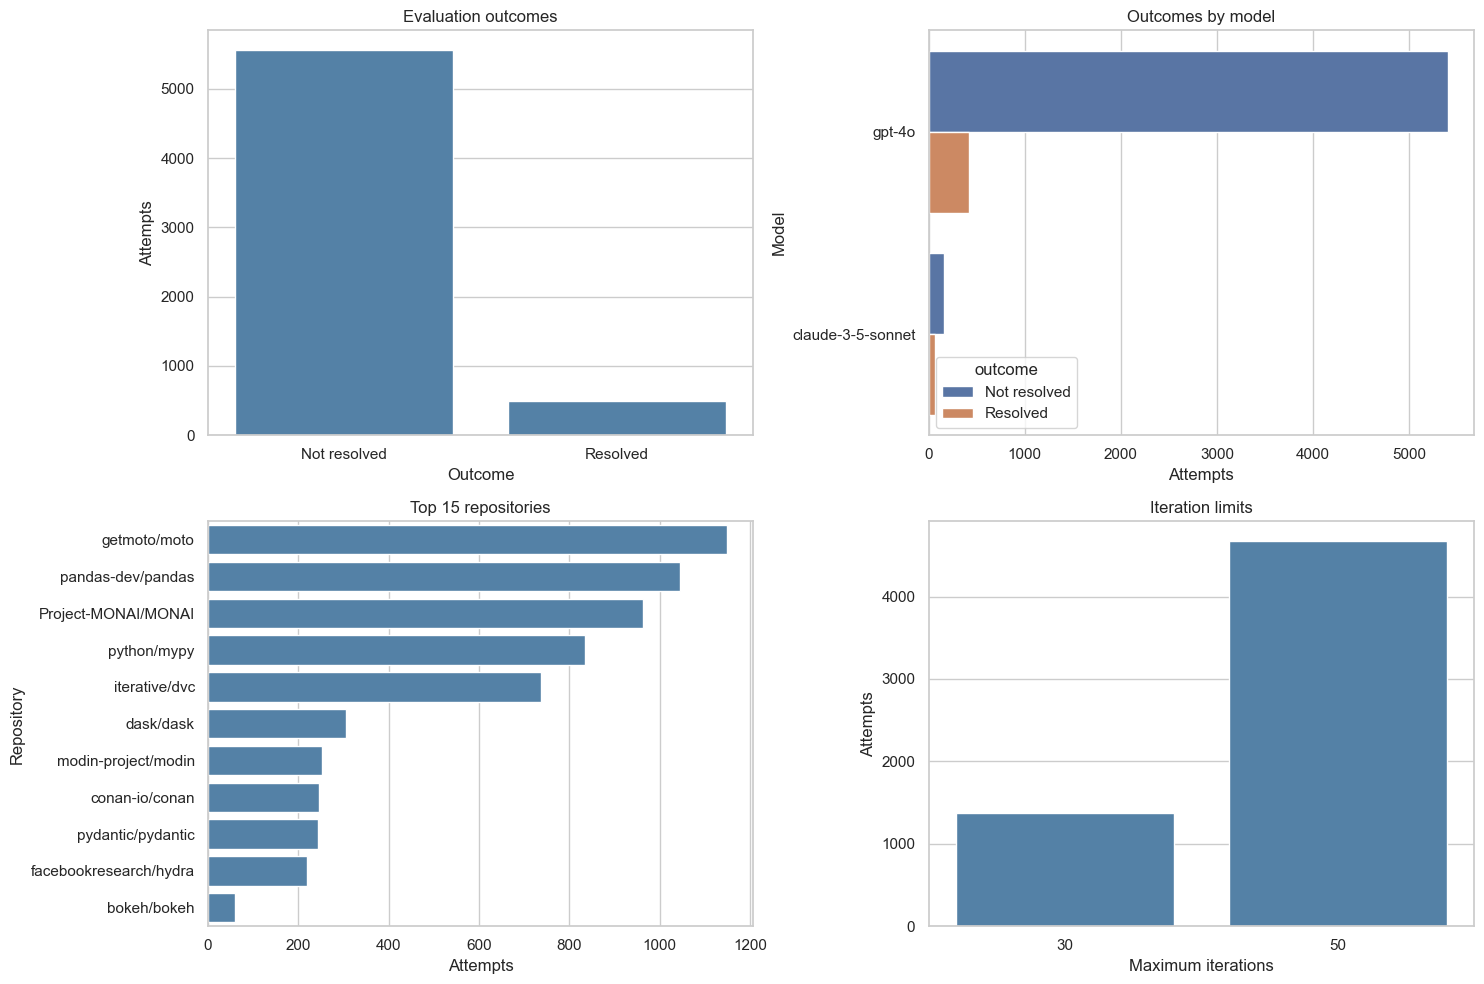

✓ Displayed distributions; missing iteration limits: 0


In [12]:
import matplotlib.pyplot as plt

print(f"[STAGE] Plot distributions for {len(trace_df):,} attempts")
plot_trace_distributions(trace_df)
plt.show()
print(f"✓ Displayed distributions; missing iteration limits: {trace_df['max_iterations'].isna().sum()}")

### Trace length, message roles, and tool calls

Message counts include every recorded role. Tool counts show actual calls made by assistants, rather than the tools available in the definitions.

[STAGE] Summarize messages in 6,055 attempts


INFO:trace_analysis:Summarized 6055 traces: messages=237851 tool_calls=106882


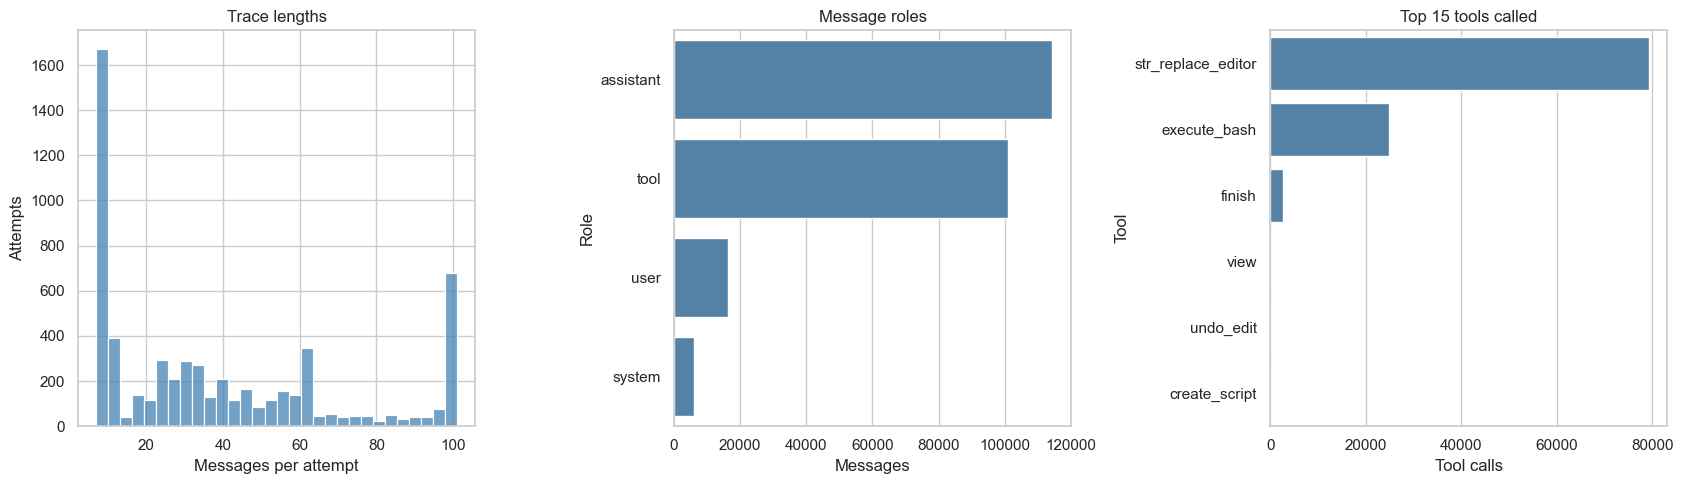

✓ Counted 237,851 messages and 106,882 tool calls


In [13]:
print(f"[STAGE] Summarize messages in {len(dataset):,} attempts")
message_counts, role_counts, tool_counts = summarize_trace_messages(dataset.select_columns(["messages"]))
plot_message_distributions(message_counts, role_counts, tool_counts)
plt.show()
print(f"✓ Counted {sum(message_counts):,} messages and {sum(tool_counts.values()):,} tool calls")

## 6. Inspect messages in order

Each table row is one message. `tool_call_id` links a tool response to its call when present. The parser decodes JSON arguments and retains invalid text with an error.

In [14]:
print(f"[STAGE] Parse messages for sample {sample_index}")
trace = SWEGymTraceAdapter().parse(sample)
messages = [asdict(message) for message in trace.messages]
message_df = pd.DataFrame(messages)
print(f"✓ Parsed {len(messages)} messages")
display(message_df[["index", "role", "tool_call_id", "content", "tool_calls"]])

[STAGE] Parse messages for sample 0
✓ Parsed 13 messages


,index,role,tool_call_id,content,tool_calls
0,0,system,None,You are a helpful assistant that can interact with a computer to solve tasks.\n<IMPORTANT>\n* If user provides a pat...,[]
1,1,user,None,<uploaded_files>\n/workspace/getmoto__moto__3.1\n</uploaded_files>\nI've uploaded a python code repository in the di...,[]
2,2,assistant,None,,"[{'id': 'call_yvYHZVbXjUPsvihtKQVVOtI6', 'name': 'str_replace_editor', 'arguments': {'command': 'view', 'path': '/wo..."
3,3,tool,call_yvYHZVbXjUPsvihtKQVVOtI6,"OBSERVATION:\nHere's the files and directories up to 2 levels deep in /workspace/getmoto__moto__3.1, excluding hidde...",[]
4,4,assistant,None,,"[{'id': 'call_1pJhJa9YD2hFdbWDIUhuqEIV', 'name': 'str_replace_editor', 'arguments': {'command': 'view', 'path': '/wo..."
5,5,tool,call_1pJhJa9YD2hFdbWDIUhuqEIV,"OBSERVATION:\nHere's the files and directories up to 2 levels deep in /workspace/getmoto__moto__3.1, excluding hidde...",[]
6,6,assistant,None,,"[{'id': 'call_rloEZJfziaKCxcYAW5Tud0mC', 'name': 'str_replace_editor', 'arguments': {'command': 'view', 'path': '/wo..."
7,7,tool,call_rloEZJfziaKCxcYAW5Tud0mC,"OBSERVATION:\nHere's the files and directories up to 2 levels deep in /workspace/getmoto__moto__3.1, excluding hidde...",[]
8,8,assistant,None,It seems there was an issue with viewing the contents of the directory. Let me try again to explore the repository s...,"[{'id': 'call_mP50aGtV3KdCx9ggln57iIvh', 'name': 'str_replace_editor', 'arguments': {'command': 'view', 'path': '/wo..."
9,9,tool,call_mP50aGtV3KdCx9ggln57iIvh,"OBSERVATION:\nHere's the files and directories up to 2 levels deep in /workspace/getmoto__moto__3.1, excluding hidde...",[]


### Read a single message

Set `message_index` to a row from the table. Tool calls and their arguments are displayed below the message.

In [15]:
message_index = 0
message = messages[message_index]
print(f"[STAGE] Message {message_index} | role: {message['role']}")
print(message["content"] if message["content"] is not None else "(no text content)")
if message["tool_call_id"]:
    print("Tool call ID:", message["tool_call_id"])
if message["tool_calls"]:
    display(pd.DataFrame(message["tool_calls"]))
print("✓ Message displayed")

[STAGE] Message 0 | role: system
You are a helpful assistant that can interact with a computer to solve tasks.
<IMPORTANT>
* If user provides a path, you should NOT assume it's relative to the current working directory. Instead, you should explore the file system to find the file before working on it.
</IMPORTANT>

✓ Message displayed


## 7. Inspect the evaluation result

This is grading information, separate from the agent’s own messages. A failed outcome alone does not identify where the attempt went wrong.

In [16]:
print(f"[STAGE] Inspect evaluation for sample {sample_index}")
result = sample.get("test_result") or {}
print("✓ Report:")
display(pd.Series(result.get("report") or {}, name="value").to_frame())
print("Patch:", result.get("git_patch"))
print("Test output:", result.get("test_output"))

[STAGE] Inspect evaluation for sample 0
✓ Report:


,value
empty_generation,True
error_eval,False
failed_apply_patch,False
resolved,False
test_timeout,False


Patch: 
Test output: None


In [34]:
# assistant_message

In [32]:
# Inspect the first assistant tool call
assistant_message = sample["messages"][2]
tool_call = assistant_message["tool_calls"][0]

print("ASSISTANT TOOL CALL:", assistant_message['tool_calls'])
print("CALL ID:", tool_call["id"])
print("TOOL NAME:", tool_call["function"]["name"])
print("ARGUMENTS:", tool_call["function"]["arguments"])

ASSISTANT TOOL CALL: [{'function': {'arguments': '{"command":"view","path":"/workspace/getmoto__moto__3.1"}', 'name': 'str_replace_editor'}, 'id': 'call_yvYHZVbXjUPsvihtKQVVOtI6', 'index': None, 'type': 'function'}]
CALL ID: call_yvYHZVbXjUPsvihtKQVVOtI6
TOOL NAME: str_replace_editor
ARGUMENTS: {"command":"view","path":"/workspace/getmoto__moto__3.1"}


In [23]:
# Inspect the next message
response = sample["messages"][3]

print("\nRESPONSE ROLE:", response["role"])
print("RESPONSE CALL ID:", response["tool_call_id"])
print("RESPONSE:", response["content"][:500])

# Does this response belong to this call?
print(
    "MATCHED:",
    tool_call["id"] == response["tool_call_id"]
)



RESPONSE ROLE: tool
RESPONSE CALL ID: call_yvYHZVbXjUPsvihtKQVVOtI6
RESPONSE: OBSERVATION:
Here's the files and directories up to 2 levels deep in /workspace/getmoto__moto__3.1, excluding hidden items:
/workspace/getmoto__moto__3.1
MATCHED: True


In [35]:
# Does this response belong to this call?
print(
    "MATCHED:",
    tool_call["id"] == response["tool_call_id"]
)

MATCHED: True
